In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import project_helpers_ga as phg
import project_helpers_metrics as phm


In [11]:
prices = pd.read_csv("data/data.csv", index_col=0, parse_dates=True)
returns = phm.daily_returns(prices)
print(returns.shape)

(5282, 7)


In [12]:
#these are settings that will stay consistent 
POP_SIZE = 50
N_KEEP = 10
GENERATIONS = 50
RATE = 0.1
SEED = 6449

train = returns.loc['2005-10-03':'2019-12-31']

In [13]:
best, hist = phg.run_ga(train, pop_size = POP_SIZE, n_keep = N_KEEP, generations = GENERATIONS, rate = RATE, seed = SEED)

In [14]:
print(pd.Series(best, index = train.columns).map('{:.1%}'.format)) 
print(best.sum(), (best >= 0).all())
print('final fitness:', phg.fitness(best, train), 'best in last gen:', hist[-1])#prints the last in place aka the best score

EEM     0.4%
EFA     0.5%
GLD    16.4%
IWM     3.5%
SPY    29.7%
TLT    47.3%
VNQ     2.1%
dtype: str
1.0 True
final fitness: 1.0511137974426112 best in last gen: 1.0498774920763176


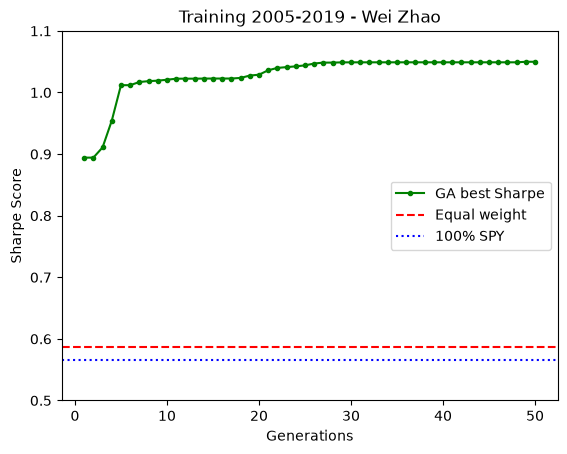

In [15]:
gens = range(1, len(hist) + 1)# counts from 1-50

equal_train = phg.fitness(np.ones(7) / 7, train) # baselines for comparison
spy_train = phg.fitness(np.array([0, 0, 0, 0, 1, 0, 0]), train) # only invests in SPY

plt.plot(gens, hist, label='GA best Sharpe', marker='.', color='green')
plt.axhline(equal_train, linestyle='--', color='red', label='Equal weight')   # flat dashed line
plt.axhline(spy_train, linestyle=':', color='blue', label='100% SPY')
plt.ylim(0.5, 1.1)
plt.title('Training 2005-2019 - Wei Zhao')            
plt.xlabel('Generations')
plt.ylabel('Sharpe Score')
plt.legend()
plt.savefig('figures/ga_fitness_history.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
weights = pd.Series(best, index=train.columns, name='weight')# each weight labeled with its ticker
weights.to_csv('data/weights.csv')

In [17]:
w = pd.read_csv("data/weights.csv", index_col=0)
print(w)

       weight
EEM  0.003813
EFA  0.005332
GLD  0.164124
IWM  0.034872
SPY  0.297258
TLT  0.473422
VNQ  0.021179
